<a href="https://colab.research.google.com/github/govindgawade0718/CSL701-17-Machine-Learning-Lab/blob/main/Experiments/9ML_Experiment_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 9
Student Name :Govind Gurunath Gawade

Batch :CS01


Roll Number :CS17



### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extended The Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load the Palmer Penguins Extended dataset
df = pd.read_csv('/content/palmerpenguins_extended.csv')
display(df.head())
print(f"Dataset Shape: {df.shape}")

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,diet,life_stage,health_metrics,year
0,Adelie,Biscoe,53.4,17.8,219.0,5687.0,female,fish,adult,overweight,2021
1,Adelie,Biscoe,49.3,18.1,245.0,6811.0,female,fish,adult,overweight,2021
2,Adelie,Biscoe,55.7,16.6,226.0,5388.0,female,fish,adult,overweight,2021
3,Adelie,Biscoe,38.0,15.6,221.0,6262.0,female,fish,adult,overweight,2021
4,Adelie,Biscoe,60.7,17.9,177.0,4811.0,female,fish,juvenile,overweight,2021


Dataset Shape: (3430, 11)


# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [ ]:
# Check for missing values
print("Missing values before preprocessing:")
print(df.isnull().sum())

# Drop rows with missing values in key columns
df_clean = df.dropna(subset=['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'species'])

# Define features (X) and target (y)
features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
X = df_clean[features]
y = df_clean['species']

# Encode categorical target using LabelEncoder
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print(f"\nProcessed Features Shape: {X.shape}")
print(f"Target classes: {le.classes_}")

Missing values before preprocessing:
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
diet                 0
life_stage           0
health_metrics       0
year                 0
dtype: int64

Processed Features Shape: (3430, 4)
Target classes: ['Adelie' 'Chinstrap' 'Gentoo']


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [ ]:
# Split dataset into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (2744, 4)
Testing set shape: (686, 4)


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [ ]:
# Initialize Decision Tree Classifier using Gini impurity
cart_model = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42)

# Fit the model
cart_model.fit(X_train, y_train)

# Make predictions on test set
y_pred_cart = cart_model.predict(X_test)
print("CART Classifier successfully trained and predictions generated.")

CART Classifier successfully trained and predictions generated.


# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

CART Model Accuracy: 0.5671

Confusion Matrix:


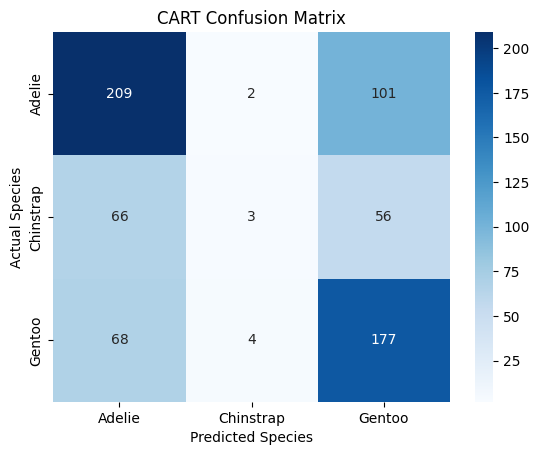


Classification Report:
              precision    recall  f1-score   support

      Adelie       0.61      0.67      0.64       312
   Chinstrap       0.33      0.02      0.04       125
      Gentoo       0.53      0.71      0.61       249

    accuracy                           0.57       686
   macro avg       0.49      0.47      0.43       686
weighted avg       0.53      0.57      0.52       686



In [ ]:
# Evaluate CART model performance
accuracy_cart = accuracy_score(y_test, y_pred_cart)
print(f"CART Model Accuracy: {accuracy_cart:.4f}\n")

print("Confusion Matrix:")
cm_cart = confusion_matrix(y_test, y_pred_cart)
sns.heatmap(cm_cart, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title("CART Confusion Matrix")
plt.ylabel('Actual Species')
plt.xlabel('Predicted Species')
plt.show()

print("\nClassification Report:")
print(classification_report(y_test, y_pred_cart, target_names=le.classes_))

# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


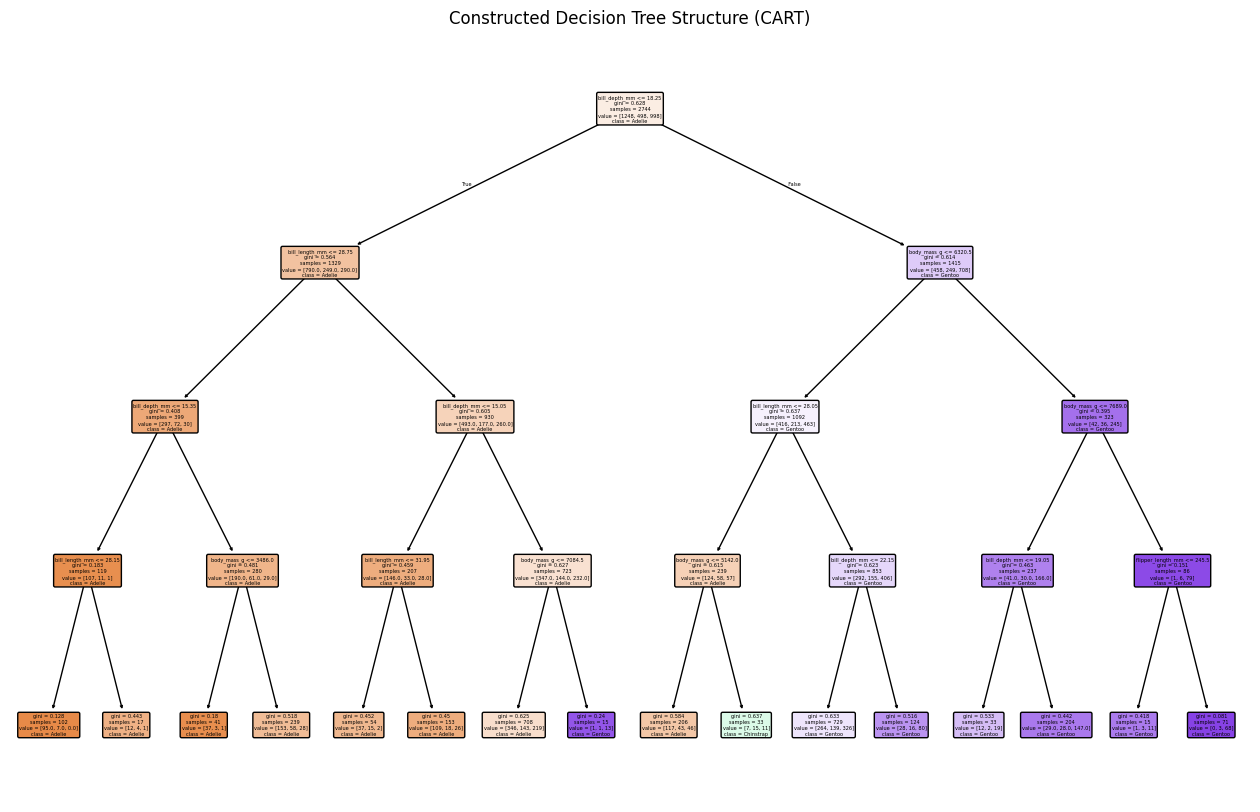

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


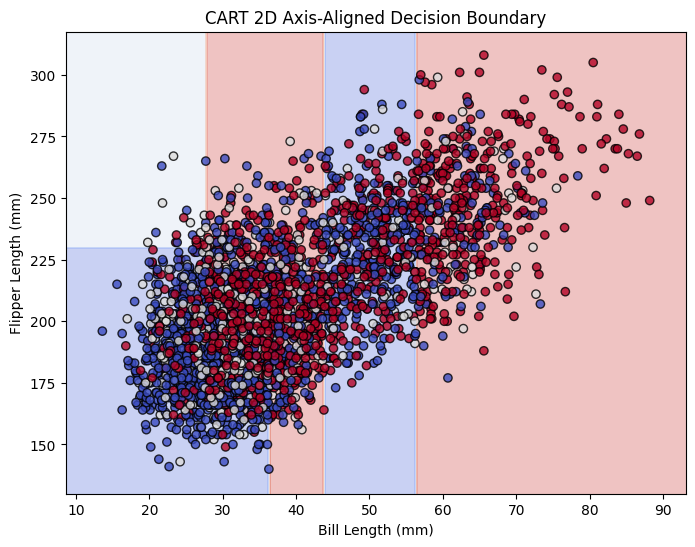

In [ ]:
# Visualize the Decision Tree structure
plt.figure(figsize=(16, 10))
plot_tree(cart_model, feature_names=features, class_names=le.classes_, filled=True, rounded=True)
plt.title("Constructed Decision Tree Structure (CART)")
plt.show()

# Select 2-D Features
X_2d = df_clean[['bill_length_mm', 'flipper_length_mm']]
y_2d = y_encoded

# Train a model on 2-D features for decision boundary plotting
cart_2d = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42)
cart_2d.fit(X_2d, y_2d)

# Plotting function helper for decision boundary
def plot_decision_boundary(model, X_data, y_data, title):
    x_min, x_max = X_data.iloc[:, 0].min() - 5, X_data.iloc[:, 0].max() + 5
    y_min, y_max = X_data.iloc[:, 1].min() - 10, X_data.iloc[:, 1].max() + 10
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.5),
                         np.arange(y_min, y_max, 0.5))

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    scatter = plt.scatter(X_data.iloc[:, 0], X_data.iloc[:, 1], c=y_data,
                          edgecolors='k', cmap=plt.cm.coolwarm, alpha=0.8)
    plt.xlabel('Bill Length (mm)')
    plt.ylabel('Flipper Length (mm)')
    plt.title(title)

plt.figure(figsize=(8, 6))
plot_decision_boundary(cart_2d, X_2d, y_2d, "CART 2D Axis-Aligned Decision Boundary")
plt.show()

# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


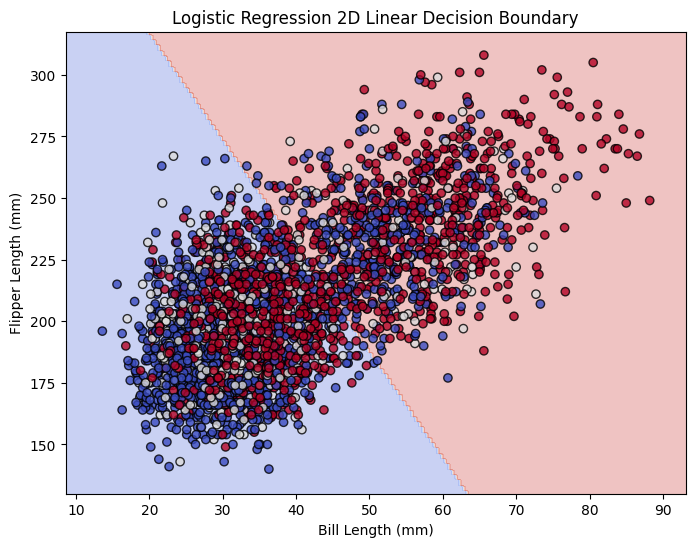

In [ ]:
# Train Logistic Regression on the same two features
lr_2d = LogisticRegression(max_iter=1000, random_state=42)
lr_2d.fit(X_2d, y_2d)

plt.figure(figsize=(8, 6))
plot_decision_boundary(lr_2d, X_2d, y_2d, "Logistic Regression 2D Linear Decision Boundary")
plt.show()

# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


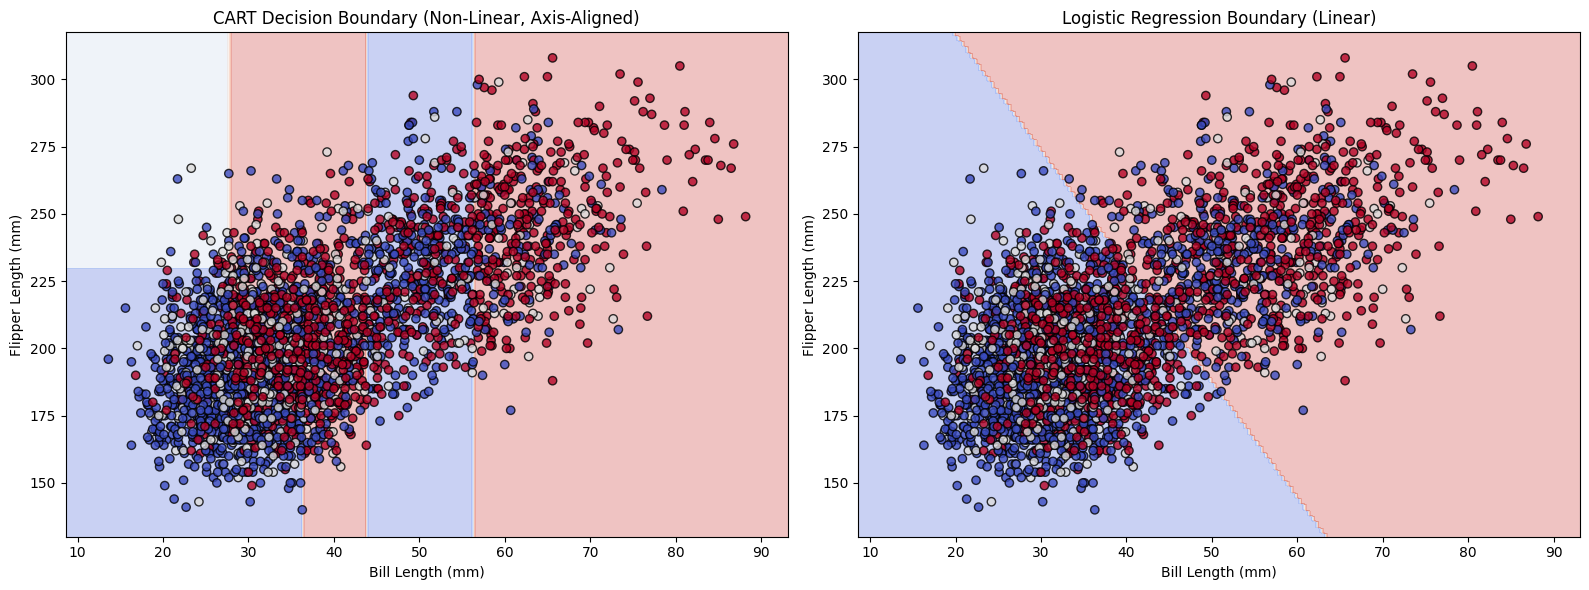

In [ ]:
# Side-by-side comparison of decision boundaries
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot CART
plt.subplot(1, 2, 1)
plot_decision_boundary(cart_2d, X_2d, y_2d, "CART Decision Boundary (Non-Linear, Axis-Aligned)")

# Plot Logistic Regression
plt.subplot(1, 2, 2)
plot_decision_boundary(lr_2d, X_2d, y_2d, "Logistic Regression Boundary (Linear)")

plt.tight_layout()
plt.show()

# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

# Train and evaluate full Logistic Regression model using all 4 features
lr_model = LogisticRegression(max_iter=2000, random_state=42)
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

accuracy_lr = accuracy_score(y_test, y_pred_lr)

# Contrast performance comparison
print("=== Performance Comparison (CART vs Logistic Regression) ===\n")
print(f"CART Classifier Accuracy:        {accuracy_cart:.4f}")
print(f"Logistic Regression Accuracy:    {accuracy_lr:.4f}\n")

print("--- CART Classification Report ---")
print(classification_report(y_test, y_pred_cart, target_names=le.classes_))

print("--- Logistic Regression Classification Report ---")
print(classification_report(y_test, y_pred_lr, target_names=le.classes_))